<a href="https://colab.research.google.com/github/chrismji/Datasci-and-Ai-in-Bus/blob/main/HW2_Admissions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 2: Graduate admissions case study

## REMEMBER TO SAVE THIS NOTEBOOK TO YOUR OWN GOOGLE DRIVE!

###Please submit homework to Brightspace in the form of a file named **`lastname_firstname.ipynb`**


**Note about AI:** I encourage you to turn off "AI-powered in-line completions" for this notebook.  You can toggle on and off from `Settings => AI Assistance`.  But I encourage you to try the coding yourself and checking it with Gemini, rather than having Gemini code for you.


You've been hired by Hudson University as a data analyst for the Graduate Admissions Department. Since the admission process is long and tedious, it often results in a bottleneck for other subsequent tasks, such as planning the necessary resources to accommodate the admitted students (e.g. housing, classes, etc). You have been asked to build a model to predict which students will be admitted, based on data from their application.

To facilitate building a model, we have collected historical data on a number of students, and asked an expert (who has been part of the admissions process) to assess the Chance of Admission.  This is the target for our model.   

We have the following data

1. Serial No. (serves as unique identifier)
2. GRE Scores (out of 340)
3. TOEFL Scores (out of 120)
4. University Rating (out of 5).
5. Statement of Purpose Strength (out of 5)
6. Letter of Recommendation Strength (out of 5)
7. Undergraduate GPA (out of 10)
8. Research Experience (either 0 or 1)
9. Chance of Admission (probability ranging from 0 to 1) [ target variable ]


Since future student applications will contain these features, a model predicting Chance of Admission from the features could be helpful in early processing of the applications.  


## Download and import the data


[Clicking here should download the data to your machine](https://drive.google.com/uc?export=download&id=1qegVDL95gjRy1P3rz7Ue43AzZG7SA1Mm) as a file called HudsonU.csv.  Place this file on your local machine for upload in the next section..

In [5]:
# import the key Python packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Trick to display plots inline with the rest of your notebook.
%matplotlib inline

Upload the HudsonU data into Colab as we have done in class, using the folder icon 📂 and the upload arrow ⬆ on the left menu. Then input the data into a pandas data frame

In [6]:
# change  NAME_OF_YOUR_FILE to input the data file you just imported into a data frame called "admissions"

df = pd.read_csv('HudsonU.csv')

**1. Is this a supervised or unsupervised problem?  Is it classification or regression?**

Supervised problem- given admissions outcomes to train off of
Regression- although the problem could easily be a classification problem, we are given and training off data on *chance* of admission, which is a continous numerical variable, making this a regression problem

**2. How many rows and columns are in the data?  Calculate whether any of the features have missing data.**

In [7]:
print(f'{df.shape[0]} rows\n{df.shape[1]} columns')

500 rows
9 columns


In [8]:
df.isnull().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

there is no missing data.

**3. Rename the columns in the dataframe to remove any blank spaces and symbols in the column (feature) names, to make them easier to refer to. This will make your life easier.  Show descriptive statistics for the newly-named columns using `describe()` - make sure output only has 2 decimal places.**

In [9]:
df = df.rename(columns = lambda i: i.replace('.',''))
df.describe().round(2)

,Serial No,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,250.50,316.47,107.19,3.11,3.37,3.48,8.58,0.56,0.72
std,144.48,11.30,6.08,1.14,0.99,0.93,0.60,0.50,0.14
min,1.00,290.00,92.00,1.00,1.00,1.00,6.80,0.00,0.34
25%,125.75,308.00,103.00,2.00,2.50,3.00,8.13,0.00,0.63
50%,250.50,317.00,107.00,3.00,3.50,3.50,8.56,1.00,0.72
75%,375.25,325.00,112.00,4.00,4.00,4.00,9.04,1.00,0.82
max,500.00,340.00,120.00,5.00,5.00,5.00,9.92,1.00,0.97


**4. Explore histograms of your features. Using `layout=(3,3)` as an option to .`.hist()` plot a  3x3 matrix of histogram of all of your numeric features (refer to our notebook `T3_Dataviz` for the code if needed).   Since the default histogram in `matplotlib` is kind of ugly, use options: `bins=25, edgecolor='black', figsize=(15, 10)` Change the colors if you like!  Finally add a sentence or two about what you learn from the histogram about the distribution of Chance_of_Admit.**

array([[<Axes: title={'center': 'Serial No'}>,
        <Axes: title={'center': 'GRE Score'}>,
        <Axes: title={'center': 'TOEFL Score'}>],
       [<Axes: title={'center': 'University Rating'}>,
        <Axes: title={'center': 'SOP'}>, <Axes: title={'center': 'LOR'}>],
       [<Axes: title={'center': 'CGPA'}>,
        <Axes: title={'center': 'Research'}>,
        <Axes: title={'center': 'Chance of Admit'}>]], dtype=object)

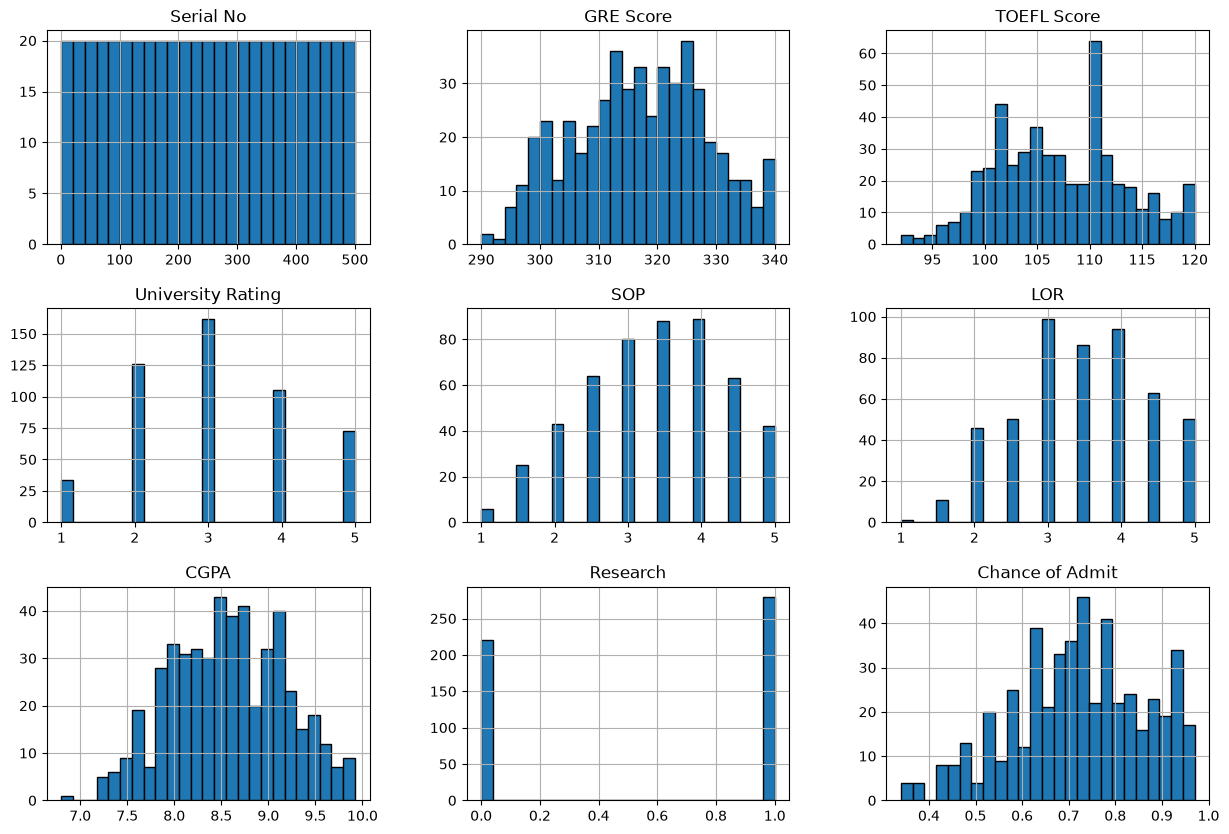

In [10]:
df.hist(layout=(3,3), bins=25, edgecolor='black', figsize=(15,10))

**5. Chance of Admission seems to vary quite a bit from student to student. How much of this depends on their research experience? Find the average Chance of Admission for the different levels of Research. (this can be done using a `groupby`) - add a sentence interpreting the results.**

In [11]:
df.groupby(['Research'])['Chance of Admit'].mean()

Research
0    0.634909
1    0.789964
Name: Chance of Admit, dtype: float64

Having prior research experience seems to significantly increase your admission oddds to Hudson U.

**6. Another way to look at the relationship between two variables is through scatter plots. Plot a scatter plot between TOEFL Score and Chance of Admission.  Use an `alpha` value less than 0.5 in order to see where there is overplotting.   Make sure to label the axes. Comment:  How would you describe this relationship?**

Text(0, 0.5, 'Chance of Admit')

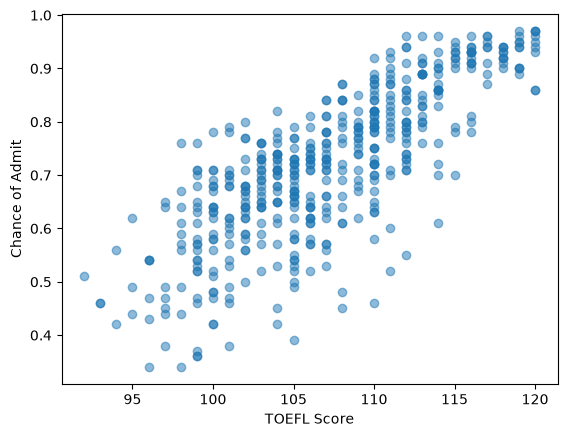

In [12]:
plt.scatter(data=df, x='TOEFL Score', y='Chance of Admit', alpha=0.5)
plt.xlabel('TOEFL Score')
plt.ylabel('Chance of Admit')

There is a significant positive correlation between an applicant's TOEFL score and their chance of admission. The applicants with higher TOEFL scores tend to have consistenly higher chance of admissions, without many significant exceptions to this trend.

**7. Boxplots are useful to look at the relationship between a categorical variable and a numeric variable. Plot a boxplot of chance of Admission grouped by "University Rating". (check out `.boxplot()` in the *seaborn* library).  Comment on any relationship you see.**

<Axes: xlabel='University Rating', ylabel='Chance of Admit'>

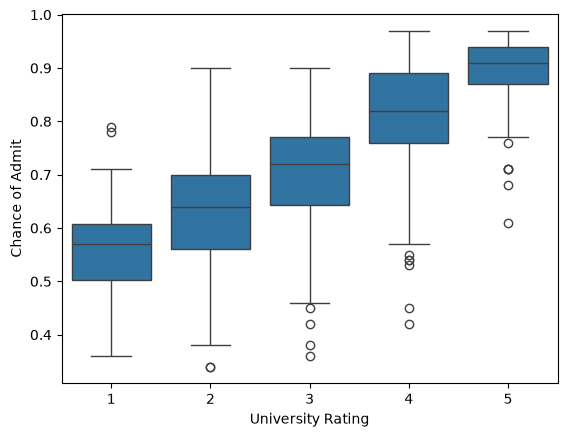

In [13]:
sns.boxplot(data=df, y='Chance of Admit', x='University Rating')

As expected, applying from a higher-rated undergraduate university tends to significantly raise your chance of admission. 
It should be noted that most of the outliers are with *lower* chance of admissions; it's overall more likely for a student to have a lower admission chance than expected from their university, rather than th eother way around.

**8. The boxplots above show some potential outliers.  In particular the box for 'University Rating' = 5 has some cases with lower Chance of Admission than the other applications with Rating = 5. Can you identify which case (by serial number) has the lowest Chance of admission but comes from a university with Rating = 5? Print out the data row for that student. What explanation is there  for why this student is given a smaller chance of admission?**


In [24]:
df[df['University Rating']==5].sort_values(by='Chance of Admit').head(1)

,Serial No,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
110,111,305,108,5,3.0,3.0,8.48,0,0.61


The rest of this student's stats do not reflect the quality of the university that they are applying from.
The rest of their statistics are mediocre and slightly below average (3.0 statement and letters, 108 TOEFL), and in particular their GRE is near the bottom of all applicants at 305.

**9. Drop the column for Serial Number. It is not useful for the following summarization and modelling tasks.**

In [27]:
df.drop(columns=['Serial No'], inplace=True)
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


**10. Display the correlations between all pairs of features using the heatmap function in seaborn. Round values to two decimal places. (use appropriate color palette and max/min values - See our `T3_DataViz.ipynb` Module for hints ).**

<Axes: >

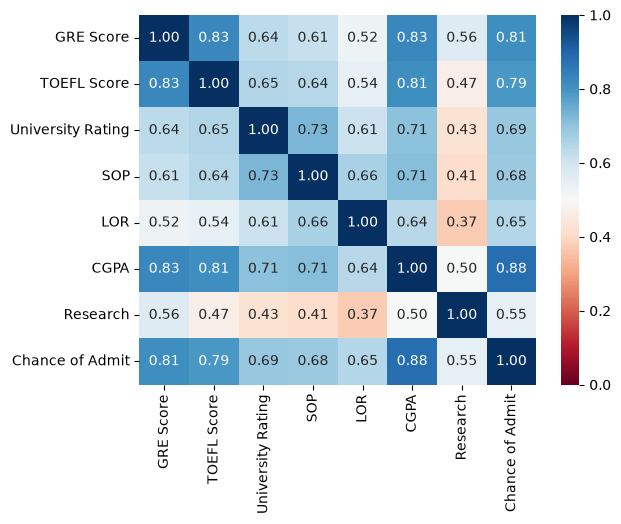

In [44]:
corr = df.corr()
sns.heatmap(corr, xticklabels=corr.columns, yticklabels=corr.columns, cmap='RdBu', fmt=".2f", vmin=0, vmax=1, annot=True)

**11. Based on this heatmap, which feature has the highest correlation with our target?**

A student's college GPA has the highest correlation with their admission odds, followed somewhat closely by their GRE and TOEFL scores.

**12. Build a linear regression model (using `LinearRegression` from `sklearn.linear_model`) to predict the Chance of Admission using the available features. Use an 80/20 training/test split.  Generate predictions and plot a scatterplot of the predicted values against the actual values using the test set. What do you learn from this plot?**


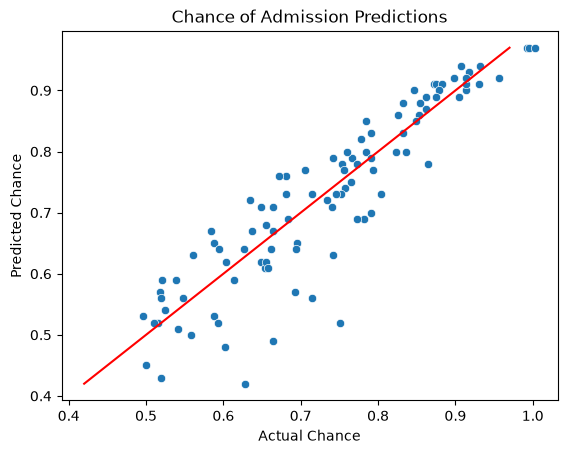

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df.drop(columns=['Chance of Admit'])
y = df['Chance of Admit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=604
)

# Build and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

# Predicted vs actual scatterplot
sns.scatterplot(x=y_pred, y=y_test)

plt.xlabel('Actual Chance')
plt.ylabel('Predicted Chance')
plt.title('Chance of Admission Predictions')

# Reference line: perfect predictions
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')

plt.show()

**13. Report the Root Mean Squared Error (RMSE) for your predictions (don't forget to round!).  Comment with an interpretion of the meaning of the RMSE.**

In [49]:
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(y_test, y_pred) ** 0.5
print(round(rmse,3))

0.061


RMSE of 0.061 means that the model's predictions are typically about 0.061/6.1% off of the real admission chance. This is quite close and indicates that the model is reasonably accurate when trying to predict a given student's chance of admission.

**14. Describe how the admissions team might take action to use the results of this model to aid in the admissions process.  Specifically what actions could they take, and what might the impact be of an effective model.  Name two other features you might consider collecting that could make this model more predictive.**

This model could be used as a sort of "screener" to help improve the admissions office's effeciency, flagging predicted high acceptance chances and perhaps allowing these applications to skip some of the admissions process.

In my opinion, the most effective use of this kind of model (AFAIK, most colleges have done some form of this for quite some time now) would be as a screener to automatically reject students with low enough stats such that their application would have been denied anyway. However, I would be wary of using this specific model in that manner; for most of the outliers the model's predicition was a significant underestimate, so trying to use this model could easily result in uniquely qualified students being unfairly rejected from Hudson. This model could maybe be tuned to be consistent and perhaps more optimistic on admissions odds.

The first potential new feature that comes to mind would be something like work/internship experience or something similar? I think it would be useful to have more features that can represent the applicant's extracurricular history beyond a simple binary 'research experience' feature. It could potentially even determine prestige of an internship through a database (this concept could also maybe be applied to the existing research feature; maybe quality of publications if they exist)

Another idea is perhaps to record grades by year. It's common for students to struggle to adapt in their early years; so being able to isolate their more recent grades would be useful for a better representation of their academic performance.

Quality of an applicant interview could be interesting, though interviews are generally only given to the most promising applicants and this model is most useful before that stage (is this an example of data leakage?).